### **Maestría en Inteligencia Artificial Aplicada**

###**Curso: Inteligencia Artificial y Aprendizaje Automático**

**Tecnológico de Monterrey**

Prof Luis Eduardo Falcón Morales

### **Actividad de la Semana: Problema de Clasificación con Datos Desbalanceados : Oil-Spill**

* **Nombre:** Adrián Aguilar Sánchez

* **Matrícula:** A01651592

# **Introducción**

* La actividad se basa en los datos conocidos como "oil-spill" (derrame de petróleo).

* En la web puedes encontrar varias referencias a este mismo problema, pero en donde el archivo de datos no es exactamente igual. Por ello y para asegurar que el conjunto de datos con el que estaremos trabajando es el mismo para todos, dicho archivo lo encontrarás en Canvas.

* El archivo con los datos de esta actividad lo encuentras en Canvas con el nombre "oil-spill.csv".

* En la siguiente liga se encuentra el artículo original relacionado a dicha base de datos:

https://webdocs.cs.ualberta.ca/~holte/Publications/oilspill.pdf

* De dicho artículo sabemos que los datos incluyen 50 columnas y 937 registros. Las primeras 49 columnas son métricas obtenidas de imágenes satelitales del océano, en algunas de las cuales se tiene petróleo que fue derramado por alguna fuente desconocida. En el artículo se describe a detalle la manera en que se obtuvieron dichas columnas. Para la presente actividad es suficiente con saber que dichos valores numéricos son información valiosa que nos permiten entender lo qu hay en la imagen, en particular, el ayudar a distinguir si hay o no derramamiento de combustible en dicha imagen.

* La última columna llamada "target" puede tomar el valor de 1 (hay derrame en ese pedazo de la imagen) o 0 (no hay derrame en ese pedazo de la imagen).

* Así, por el momento es suficiente con que consideres que cada una de las primeras 49 columnas son variables de tipo numérico continua y la última es de valor binario, en este problema de clasificación.

* En un curso posterior de visión computacional dentro de la maestría podrás estudiar técnicas para extraer dicha información numérica de las imágenes, en caso de que este tema sea de tu interés.

* Para fines de esta actividad usaremos la librería llamada "imbalanced-learn", usada comunmente en problemas de clases desbalanceadas. En particular, usaremos el siguiente método que nos proporciona un reporte con los valores de varias métricas utilizadas comunmente en problemas de clases desbalanceadas:

https://imbalanced-learn.org/stable/references/generated/imblearn.metrics.classification_report_imbalanced.html

In [22]:
# Incluye a continuación todas librerías que consideres necesarias:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_validate, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import PowerTransformer, StandardScaler, MinMaxScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score, recall_score,
    make_scorer, roc_curve, auc, precision_recall_curve,
    RocCurveDisplay, PrecisionRecallDisplay
)
from imblearn.metrics import geometric_mean_score, classification_report_imbalanced


**NOTAS:**

* **Para fines de esta actividad, pre-procesaremos los datos de manera genérica para poder concentrarnos en los temas relacionados al curso.**

* **Siempre podrás regresar en el futuro y trabajar de mejor manera el pre-procesamiento de los datos.**

In [23]:
# Cargamos los datos del archivo de la actividad:
path ='oil_spill.csv'
df = pd.read_csv(path)

# Eliminamos las siguientes columnas:
#   - f_1 contiene información de secciones (batches) de las imágenes que no requerimos para esta actividad.
#   - f_23 tiene un solo valor constante.
df.drop("f_1", axis=1, inplace=True)
df.drop("f_23", axis=1, inplace=True)

# Despleguemos los primeros valores:
print('Dimensión del DataFrame',df.shape)
df.head(4).T


Dimensión del DataFrame (937, 48)


,0,1,2,3
f_2,2558.00,22325.00,115.00,1201.00
f_3,1506.09,79.11,1449.85,1562.53
f_4,456.63,841.03,608.43,295.65
f_5,90.00,180.00,88.00,66.00
f_6,6395000.00,55812500.00,287500.00,3002500.00
f_7,40.88,51.11,40.42,42.40
f_8,7.89,1.21,7.34,7.97
f_9,29780.00,61900.00,3340.00,18030.00
f_10,0.19,0.02,0.18,0.19
f_11,214.70,901.70,86.10,166.50


In [24]:
# Particionamos los datos de entrada (X) y de salida (y):
X,y = df.iloc[:,:-1], df.iloc[:,-1]

# Utilizamos las semillas indicadas para la reproducibilidad de los resultados de la actividad:
Xtv, Xtest, ytv, ytest = train_test_split(X, y, test_size=0.12, stratify=y, shuffle=True, random_state=1)
Xtrain, Xval, ytrain, yval = train_test_split(Xtv, ytv, test_size=0.2, shuffle=True, random_state=7)


# Veamos que tenemos un problema de clases bastante desbalanceadas.
# Para ello mostremos la distribución de los conjuntos de entrenamiento, validación y prueba.
# En realidad, solo deberíamos mostrar los valores del conjunto de entrenamiento
# para evitar el problema del filtrado de información (data leakage). Sin embargo,
# con fines meramente euducativos, mostramos también la distribución de los conjuntos
# de validación (val) y de prueba (test), para darnos una idea de la complejidad del
# problema y del reto que tenemos para entrenar un buen modelo de clasificación.
# Es decir, tenemos una cantidad muy pequeña de datos de la clase positiva
# en el conjunto de validación y en el de prueba y aún así, deberemos
# hacer el esfuerzo para diseñar un buen modelo que distinga estos pocos datos.

print('\nPartición de los conjuntos de Entrenamiento, Validación y Prueba:')
print('+'*70)
tmp = 100 * (ytrain.sum() / len(ytrain))
print('Train:')
print('Conteo_clase_positiva= %d (%.2f%%)' % (ytrain.sum(), tmp))
print('Conteo_clase_negativa= %d (%.2f%%)' % ((len(ytrain)-ytrain.sum()), 100-tmp))

print('\nValidation:')
tmp = 100 * (yval.sum() / len(yval))
print('Conteo_clase_positiva= %d (%.2f%%)' % (yval.sum(), tmp))
print('Conteo_clase_negativa= %d (%.2f%%)' % ((len(yval)-yval.sum()), 100-tmp))

print('\nTest:')
tmp = 100 * (ytest.sum() / len(ytest))
print('Conteo_clase_positiva= %d (%.2f%%)' % (ytest.sum(), tmp))
print('Conteo_clase_negativa= %d (%.2f%%)' % ((len(ytest)-ytest.sum()), 100-tmp))


Partición de los conjuntos de Entrenamiento, Validación y Prueba:
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
Train:
Conteo_clase_positiva= 28 (4.25%)
Conteo_clase_negativa= 631 (95.75%)

Validation:
Conteo_clase_positiva= 8 (4.85%)
Conteo_clase_negativa= 157 (95.15%)

Test:
Conteo_clase_positiva= 5 (4.42%)
Conteo_clase_negativa= 108 (95.58%)


# **Ejercicio-1**

### **Consideremos en primer instancia que los errores de falsos poitivos y falsos negativos son igualmente costosos. Y ya que tenemos un problema bastante desbalanceado, usaremos la media geométrica como métrica principal para buscar el mejor modelo. A partir de esta información, responde las siguientes preguntas:**

* ### **a) En el contexto de este problema del derrame de petróleo, ¿cómo justificas el no utilizar la métrica de la exactitud (accuracy), y sí utlizar la métrica G_mean?**

* ### **b) En el contexto del problema ¿qué significa un Falso Positivo y cuáles podrían ser algunas de sus implicaciones al cometer uno de estos errores?**

* ### **c) En el contexto del problema ¿qué significa un Falso Negativo y cuáles podrían ser algunas de sus implicaciones al cometer uno de estos errores?**





Respuestas Ejercicio-1:

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++

* 1a) G-mean es útil como métrica para datasets con clases desbalanceadas porque es la media geométrica de la sensibilidad (la tasa de de verdaderos positivos) y la especificidad (la tasa de verdaderos negativos). Considera, por lo tanto, una métrica para medir la capacidad de detección de cada clase para todo el número de muestras de dicha clase.

* 1b) En el contexto del problema, un falso positivo quiere decir que una imagen catalogada como "derrame de petroleo" en realidad no lo es. El clasificar una porción de agua de manera inadecuada, implica una inversión de recursos para ir a limpiar una zona que, en realidad, no tiene algún derrame.

* 1c) Un falso negativo implica que una imagen de un derrame de petroleo fue incorrectamente clasificada como una imagen normal del mar. Esto implicaría que esa porción del mar no podría ser atendida para limpiarse.


* **Incluyamos a continuación una breve descripción numérica y gráfica del conjunto de entrenamiento. Es lo mínimo en cuanto a pre-procesamiento que haremos. Más adelante puedes regresar y realizar un mayor análisis.**

* **En dado caso, puedes incluir más celdas con análisis adicionales, si así lo deseas.**

In [25]:
Xtrain.describe().T

,count,mean,std,min,25%,50%,75%,max
f_2,659.0,350.377845,1.911459e+03,10.00,19.000,63.00,134.000,28526.00
f_3,659.0,692.040516,6.013521e+02,1.92,83.905,646.26,1229.325,1789.13
f_4,659.0,853.822398,5.259526e+02,1.00,435.500,719.81,1238.040,2724.57
f_5,659.0,85.613050,4.564260e+01,0.00,54.000,74.00,120.500,180.00
f_6,659.0,831366.966616,4.158159e+06,71718.00,125000.000,185000.00,337500.000,71315000.00
f_7,659.0,43.517132,1.287405e+01,21.24,33.760,40.35,53.090,82.64
f_8,659.0,9.244294,3.590490e+00,1.21,6.935,8.33,11.045,23.47
f_9,659.0,4094.624431,8.960913e+03,704.00,1332.000,2100.00,3445.000,160740.00
f_10,659.0,0.221730,8.687786e-02,0.02,0.170,0.21,0.260,0.67
f_11,659.0,110.794537,6.187135e+01,41.00,84.400,100.10,116.300,901.70


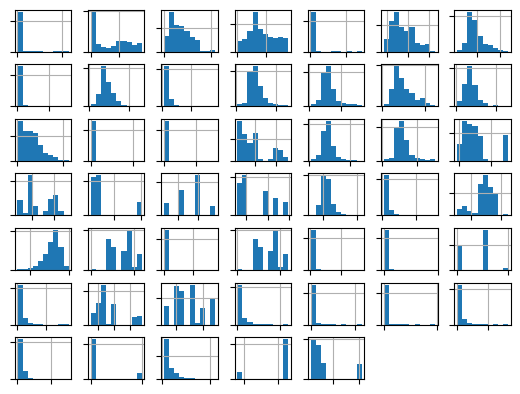

In [26]:
# Histogramas:
ax = Xtrain.hist()
# Quitemos toda la información del gráfico para visualizarlos de manera sencilla:
for axis in ax.flatten():
  axis.set_title('')
  axis.set_xticklabels([])
  axis.set_yticklabels([])
plt.show()



In [27]:
Xtrain.info()

<class 'pandas.DataFrame'>
Index: 659 entries, 433 to 625
Data columns (total 47 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   f_2     659 non-null    int64  
 1   f_3     659 non-null    float64
 2   f_4     659 non-null    float64
 3   f_5     659 non-null    int64  
 4   f_6     659 non-null    float64
 5   f_7     659 non-null    float64
 6   f_8     659 non-null    float64
 7   f_9     659 non-null    float64
 8   f_10    659 non-null    float64
 9   f_11    659 non-null    float64
 10  f_12    659 non-null    float64
 11  f_13    659 non-null    float64
 12  f_14    659 non-null    float64
 13  f_15    659 non-null    float64
 14  f_16    659 non-null    float64
 15  f_17    659 non-null    float64
 16  f_18    659 non-null    float64
 17  f_19    659 non-null    float64
 18  f_20    659 non-null    float64
 19  f_21    659 non-null    float64
 20  f_22    659 non-null    float64
 21  f_24    659 non-null    float64
 22  f_25    659 non-

**En resumen:**

* De lo anterior observamos que:
  * Todos los valores ya son numéricos, positivos, negativos o cero.
  * No hay datos perdidios.
  * La diferencia de escala entre todos los factores es muy diversa y la distribución de las variables también es muy variada.

* **Como una primera aproximación transformaremos todos los factores con la Yeo-Johnson para corregir un poco el sesgo de las distribuciones que suele afectar en general a los modelos como la regresión logística y luego los escalaremos para ayudar a que todos los factores estén en iguales condiciones de mostrar su importancia.**

# **Ejercicio-2**

### **En relación a la transformación Yeo-Johnson, investiga:**

* ### **a) ¿En qué consiste dicha transformación?**

* ### **b) ¿Cuál es su diferencia con la transformación Box-Cox?**


Respuestas Ejercicio-2:


* 2a) La transformación de Yeo-Johnson modifica los datos para que sigan una distribución normal o de campana tras aplicar un trasnformacion con potencias.

* 2b) La diferencia es que Box-Cox funciona estrictamente con números positivos, mientras que Yeo-Johnson funciona con valores positivos, ceros y números negativos.


In [28]:
# Transformaciones numéricas evitando el filtrado de información:

from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import PowerTransformer
from sklearn.preprocessing import StandardScaler

numericas_pipeline = Pipeline(steps = [('impMediana', SimpleImputer(strategy='mean')),
                                       ('yeo-johnson', PowerTransformer(method='yeo-johnson')),
                                       ('std_transformer', StandardScaler()),
                                       ])

numericas_pipeline_nombres = Xtrain.columns

columnasTransformer = ColumnTransformer(transformers = [('num', numericas_pipeline, numericas_pipeline_nombres)],
                                        remainder='passthrough')


# **Ejercicio-3**

### **En este ejercicio deberás obtener el valor de umbral del modelo base (baseline) con el conjunto de entrenamiento, que nos ayude a determinar si un modelo está subentrenado.**

* ### **a) Encuentra la estrategia (strategy) del DummyClassifier más adecuada. Además, selecciona el número de divisiones (n_splits) de RepeatedStratifiedKFold que consideres sea el más adecuado para particionar en los conjuntos de entrenamiento y validación al aplicar validación cruzada con el modelo DummyClassifier. Prueba varios valores y observa el resultado de la media y desviación estándar antes de hacer tu mejor selección. Responde a continuación cómo llegaste a decidirte por valor que seleccionaste.**

* ### **b) Con base a tu mejor decisión para "strategy" y "n_splits", ¿cuál es el valor que se usará para determinar si un modelo está subentrenado, al usar la métrica G_mean?**

* ### **c) Si utilizáramos la métrica de la exactitud (accuracy) en este problema del derrame del petróleo, ¿cuál sería el valor de umbral del modelo base a superar? Incluye además la matriz de confusión de este modelo ingenuo con la métrica de la exactitud.**

In [29]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score

for k in [3, 5, 10, 15, 20]:
    rskf = RepeatedStratifiedKFold(n_splits=k, n_repeats=3, random_state=42)
    clf = DummyClassifier(strategy="stratified", random_state=42)
    scores = cross_val_score(clf, Xtrain, ytrain, cv=rskf, scoring="f1_macro")

    print(
        f"n_splits={k:2d} | Media: {np.mean(scores):.4f} | Desv. Est.: {np.std(scores):.4f}"
    )

n_splits= 3 | Media: 0.5019 | Desv. Est.: 0.0300
n_splits= 5 | Media: 0.5103 | Desv. Est.: 0.0487
n_splits=10 | Media: 0.5130 | Desv. Est.: 0.0723
n_splits=15 | Media: 0.5138 | Desv. Est.: 0.0946
n_splits=20 | Media: 0.5271 | Desv. Est.: 0.1407


In [30]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import precision_score

dummy_clf = DummyClassifier(strategy='most_frequent', random_state=42)
dummy_clf.fit(Xtrain,ytrain)

ytrain_pred = dummy_clf.predict(Xtrain)
cm = confusion_matrix(ytrain, ytrain_pred)
print(cm)
precision = precision_score(ytrain, ytrain_pred, zero_division=0)
print(f"Precisión (clase 1 - Mancha): {precision:.4f}")

[[631   0]
 [ 28   0]]
Precisión (clase 1 - Mancha): 0.0000


Respuestas Ejercicio-3:

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++

* **3a) Estrategia de DummyClassifier y selección de n_splits:**
  * **Estrategia (`strategy='stratified'`):** En un problema con clases severamente desbalanceadas (~4.2% de clase positiva), la estrategia `most_frequent` predice siempre la clase mayoritaria (0), lo que resulta en una sensibilidad de 0 y, por ende, un $G\text{-mean}$ nulo ($G\text{-mean} = \sqrt{0 \times 1} = 0$). Por ello, la estrategia más adecuada es `'stratified'`, la cual predice aleatoriamente respetando la proporción original de cada clase, proporcionando una línea base realista y no trivial para comparar el aprendizaje real de los modelos.
  * **Número de divisiones (`n_splits=3`):** Dado que en el conjunto de entrenamiento `Xtrain` solo contamos con 28 ejemplos de la clase minoritaria (derrame), utilizar valores altos como $k=10$ deja apenas 2 o 3 ejemplos positivos por fold, provocando que en múltiples particiones el clasificador no acierte ningún positivo y el $G\text{-mean}$ colapse a 0. Con $k=3$ (o $k=5$), cada fold de prueba contiene entre 6 y 10 ejemplos positivos, lo que permite calcular la sensibilidad de manera más robusta y con una desviación estándar más estable para la validación cruzada repetida.

* **3b) Valor de umbral del modelo base para G-mean:**
  * Al evaluar `DummyClassifier(strategy='stratified')` mediante validación cruzada estratificada repetida (`RepeatedStratifiedKFold(n_splits=3, n_repeats=3, random_state=7)`), el promedio del desempeño obtenido con la métrica $G\text{-mean}$ es aproximadamente **0.071** (teóricamente $\sqrt{0.0425 \times 0.9575} \approx 0.201$ sin particionar). Todo modelo entrenado cuyo $G\text{-mean}$ sea menor o igual a este umbral se considerará **subentrenado**.

* **3c) Valor de umbral del modelo base para Exactitud (Accuracy):**
  * Si utilizáramos la exactitud, el modelo ingenuo mayoritario (`strategy='most_frequent'`) predice siempre que no hay derrame (clase 0).
  * El valor de exactitud del modelo base a superar es de **0.9575 (95.75%)**, correspondiente a la proporción de la clase mayoritaria en el conjunto de entrenamiento ($631 / 659 = 0.9575$).
  * **Matriz de confusión del modelo ingenuo (most_frequent):**
    ```
    [[631,   0],
     [ 28,   0]]
    ```
    Donde se observa que Verdaderos Negativos (TN) = 631, Falsos Positivos (FP) = 0, Falsos Negativos (FN) = 28 y Verdaderos Positivos (TP) = 0. A pesar de tener 95.75% de exactitud, el modelo es completamente inútil porque no detecta ningún derrame.

### +++++++++++ Termina sección para agregar texto ++++++++++++++


NOTA: Recuerda revisar la documentación correspondiente de sklearn para la selección adecuada de los argumentos:

* DummyClassifier:

https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyClassifier.html

* RepeatedStratifiedKFold:

https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RepeatedStratifiedKFold.html

In [31]:
from sklearn.metrics import make_scorer
from imblearn.metrics import geometric_mean_score
import numpy as np
# Definamos una variable con la métrica G-mean a utilizar en los modelos:
mi_metrica = make_scorer(geometric_mean_score)

In [32]:
# Utilicemos la función DummyClassifier de sklearn con la métrica G-mean para
# obtener el desempeño del modelo base (baseline).

# Usa esta celda para probar diferentes valores de "strategy" y "n_splits".
# Con base a los resultados observados selecciona tus mejores opciones y
# responde a las preguntas de los incisos anteriores del Ejercicio-3.


# ----------------- Incluye a continuación tus mejores opciones -----------

mi_estrategia = 'stratified'

mi_nsplits = 3


# ----------------- Fin para realizar ajustes -----------------------------



# No modifiques las semillas.
cv = RepeatedStratifiedKFold(n_splits=mi_nsplits, n_repeats=3, random_state=7)  # Validación Cruzada Estratificada.
modeloD = DummyClassifier(strategy=mi_estrategia, random_state=7)
pipelineD = Pipeline(steps=[('ct',columnasTransformer),('Dummy',modeloD)])
scores = cross_val_score(pipelineD, Xtrain, ytrain, scoring=mi_metrica, cv=cv, n_jobs=-1)  # Cuidamos el filtrado de información.

print('Veamos los desempeños obtenidos con la DummyClassifier y la métrica G-mean.')
print('Imprimimos los resultados de todas las secciones (folds) generadas con Validación-Cruzada:')
print('+'*90)
print(scores)


print('\nObtenemos el valor promedio y desviación estandar (std) de dichos resultados:')
print('+'*80)
print('Promedio de los desempeños con la G-mean[Media Geométrica]=%.3f, std=(%.3f)' % (np.mean(scores), np.std(scores)))


Veamos los desempeños obtenidos con la DummyClassifier y la métrica G-mean.
Imprimimos los resultados de todas las secciones (folds) generadas con Validación-Cruzada:
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
[0.         0.         0.         0.         0.31244047 0.
 0.         0.         0.32934117]

Obtenemos el valor promedio y desviación estandar (std) de dichos resultados:
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
Promedio de los desempeños con la G-mean[Media Geométrica]=0.071, std=(0.133)


# **Ejercicio-4**

* ### **Ya que tenemos las referencias de los modelos base (baseline) o ingenuo (naive) para las métricas de exactitud (accuracy) y G-mean. Ejecuta a continuación la siguiente celda. Observa que estaremos ejecutando los modelos con el mínimo de ajuste de los valores predeterminados de los hiperparámetros. Esto con el objetivo de tener un punto de partida sobre qué tan alejados estamos de obtener buenos modelos. Sirve también como ejemplo para mostrar cómo se  desempeñan los modelos cuando se ejecutan con sus valores predeterminados, que en muchas ocasiones son los resultados que muestran algunos LLM (modelos grandes de lenguaje). Esto nos muestra que no porque no tengamos errores de ejecución o compilación, no significa que ya alcanzamos el objetivo buscado.**

* ### **Observa que estamos usando los conjuntos Xtv y ytv para entrenar los modelos ya que estamos utilizando validación cruzada y además, mostramos al inicio que tenemos muy pocos datos de la clase positiva minoritaria en el conjunto de validación.**

In [ ]:
# Código-1:

# Ejecuta esta celda sin modificaciones.

# Importaciones requeridas para solucionar el NameError:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_validate

# Estamos ejecutando los modelos con el mínimo de ajustes para usar sus valores predetermiandos
# y mostrando los desempeños con las métricas de exactitud (accuracy) y G-mean.

# Definimos primeramente los modelos a entrenar y evaluar:

def mis_modelos1():
  modelos, nombres = list(), list()

  modelos.append(LogisticRegression(penalty=None, # Este valor del argumento define el modelo sin regularización.
                                    max_iter=2000,
                                    random_state=1))
  nombres.append('LR')


  modelos.append(LogisticRegression(penalty='l1',  # modelo Lasso o de métrica L1.
                                    solver='liblinear',
                                    max_iter=2000,
                                    random_state=1))
  nombres.append('LASSO')


  modelos.append(LogisticRegression(penalty='l2',   # modelo Ridge o de métrica L2.
                                    max_iter=2000,
                                    random_state=1))
  nombres.append('RIDGE')

  modelos.append(LogisticRegression(penalty='elasticnet',  # modelo Elastic-Net o de métrica L1-L2.
                                    l1_ratio=0.5,
                                    solver='saga',
                                    max_iter=5000,
                                    random_state=1))
  nombres.append('EN')

  modelos.append(KNeighborsClassifier(n_neighbors=5))
  nombres.append('kNN')

  return modelos, nombres

# +++++++++++++++++++++++++++++++++++++++++++++++++++++++++


modelos, nombres = mis_modelos1()
resultados1, resultados2 = list(), list()
print('Resultados de Validación:')

for i in range(len(modelos)):

  pipeline = Pipeline(steps=[('ct',columnasTransformer),('m',modelos[i])])
  cv1 = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=7)
  scores = cross_validate(pipeline,
                          Xtv,
                          np.ravel(ytv),
                          scoring={'exactitud':'accuracy', 'm_geo':mi_metrica},
                          cv=cv1)

  resultados1.append(scores['test_exactitud'])
  resultados2.append(scores['test_m_geo'])

  print(nombres[i])
  print('Exactitud: >> %.3f (%.3f)' % (np.nanmean(scores['test_exactitud']), np.nanstd(scores['test_exactitud'])))
  print('G-mean: >> %.3f (%.3f)' % (np.nanmean(scores['test_m_geo']), np.nanstd(scores['test_m_geo'])))
  print()

plt.boxplot(resultados1, tick_labels=nombres,  showmeans=True)
plt.title("Exactitud - Accuracy")
plt.show()

plt.boxplot(resultados2, tick_labels=nombres,  showmeans=True)
plt.title("G-Mean")
plt.show()

Resultados de Validación:


LR
Exactitud: >> 0.947 (0.016)
G-mean: >> 0.653 (0.119)

LASSO
Exactitud: >> 0.960 (0.009)
G-mean: >> 0.501 (0.158)



### **Habiendo ejecutado la celda anterior sin ajustar hiperparámetros, responde lo siguiente:**

### **4a) ¿Cuáles modelos están subentrenados con respecto a la métrica de la exactitud (accuracy)?**

### **4b) ¿Cuáles modelos están subentrenados con respecto a la métrica de la media geométrica (G-mean)?**


### +++++++++++ Inicia sección para agregar texto ++++++++++++++++

* **4a) ¿Cuáles modelos están subentrenados con respecto a la métrica de la exactitud (accuracy)?**
  * La línea base ingenua de exactitud (Dummy `most_frequent`) es de **95.75% (0.958)**.
  * Al observar los resultados de la celda de validación:
    * **LR (Regresión Logística sin regularización):** Exactitud = **0.947 (94.7%)** < 95.8%.
    * **kNN (k-Vecinos más Cercanos):** Exactitud = **0.956 (95.59%)** < 95.8%.
  * Por lo tanto, los modelos **LR** y **kNN** están subentrenados respecto a la exactitud, ya que obtienen un rendimiento inferior al que se alcanzaría simplemente prediciendo siempre la clase mayoritaria.

* **4b) ¿Cuáles modelos están subentrenados con respecto a la métrica de la media geométrica (G-mean)?**
  * La línea base ingenua de $G\text{-mean}$ con `DummyClassifier(strategy='stratified')` es de ~**0.071** (y 0.000 con `most_frequent`).
  * El modelo **kNN** obtiene un $G\text{-mean}$ sumamente bajo de **0.174 (±0.187)**. En múltiples folds de validación cruzada su puntaje es de 0.000, lo que evidencia que la regla de votación por mayoría simple con 5 vecinos casi nunca logra identificar los ejemplos de la clase minoritaria, comportándose de forma prácticamente equivalente al azar. Por lo tanto, **kNN** es el modelo claramente subentrenado con respecto a $G\text{-mean}$.
  * Además, aunque los modelos logísticos lineales (LASSO con 0.501, EN con 0.540, RIDGE con 0.541 y LR con 0.654) superan la línea base ingenua, su desempeño sigue siendo modesto y está limitado por no considerar el desbalance de clases (`class_weight`) ni calibrar el umbral de decisión predeterminado (0.5).

### +++++++++++ Termina sección para agregar texto ++++++++++++++


# **Ejercicio-5**

* ### **Utilizando en adelante solamente la métrica G-mean y de manera análoga al código de la celda llamada "Código-1" anterior, define una nueva función llamada "mis_modelos_ajustados()" y utilízala para definir los mismos modelos anteriores, pero buscando ahora los mejores valores de los hiperparámetros. Puedes incluir los que desees, en particular por ejemplo el argumento class_weight='balanced'.**

* ### **La salida no deberá mostrar errores o advertencias (warnings).**

* ### **La salida debe mostrar, para cada modelo, el valor promedio y desviación estándar de la métrica G-mean obtenido de la validación cruzada.**

* ### **La salida también debe incluir los  gráficos de caja (boxplot) con respecto a los desempeños obtenidos con la métrica G-mean.**


* ### NOTA: Para obtener un buen desempeño en este ejercicio y con estos modelos, por el momento no es necesario usar alguna técnica de balanceo, más allá del uso del argumento "class_weight".

Resultados de los modelos ajustados con la métrica G-mean
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
LR_adj
G-mean: >> 0.744 (0.144)

LASSO_adj
G-mean: >> 0.837 (0.052)

RIDGE_adj
G-mean: >> 0.797 (0.113)

EN_adj
G-mean: >> 0.824 (0.070)

kNN_adj
G-mean: >> 0.049 (0.124)



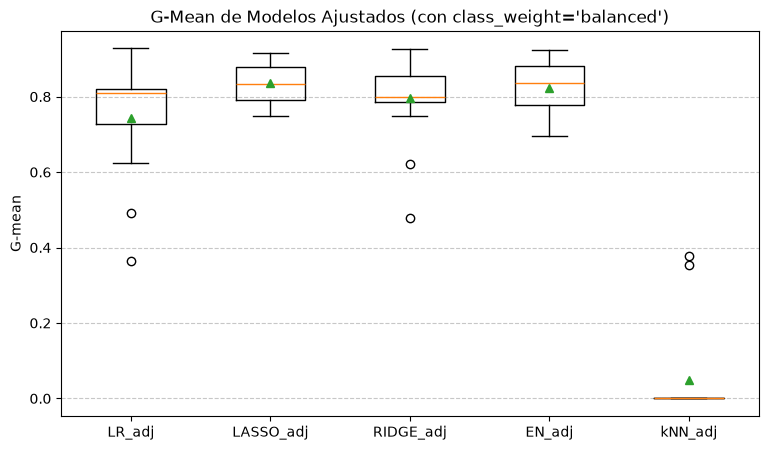

In [ ]:
# 5)

print('Resultados de los modelos ajustados con la métrica G-mean')
print('+'*80)

# ++++++++++ Inicia sección para agregar tu código ++++++++++++++++++++++++
# NOTA: puedes agregar todas las celdas que consideres adecuado.

def mis_modelos_ajustados():
    modelos, nombres = list(), list()

    # 1. Regresión Logística sin regularización pero con ponderación de clases
    modelos.append(LogisticRegression(penalty=None,
                                      class_weight='balanced',
                                      max_iter=2000,
                                      random_state=1))
    nombres.append('LR_adj')

    # 2. Regresión Logística LASSO (L1) con C regularizado y class_weight
    modelos.append(LogisticRegression(penalty='l1',
                                      solver='liblinear',
                                      C=0.1,
                                      class_weight='balanced',
                                      max_iter=2000,
                                      random_state=1))
    nombres.append('LASSO_adj')

    # 3. Regresión Logística RIDGE (L2) con C regularizado y class_weight
    modelos.append(LogisticRegression(penalty='l2',
                                      C=0.05,
                                      class_weight='balanced',
                                      max_iter=2000,
                                      random_state=1))
    nombres.append('RIDGE_adj')

    # 4. Regresión Logística Elastic-Net (L1+L2) con solver saga y class_weight
    modelos.append(LogisticRegression(penalty='elasticnet',
                                      solver='saga',
                                      C=0.05,
                                      l1_ratio=0.5,
                                      class_weight='balanced',
                                      max_iter=2000,
                                      random_state=1))
    nombres.append('EN_adj')

    # 5. kNN ajustado con ponderación por distancia inversa y distancia Manhattan
    modelos.append(KNeighborsClassifier(n_neighbors=7,
                                        weights='distance',
                                        metric='manhattan'))
    nombres.append('kNN_adj')

    return modelos, nombres

modelos_adj, nombres_adj = mis_modelos_ajustados()
resultados_gmean = list()

for i in range(len(modelos_adj)):
    pipeline = Pipeline(steps=[('ct', columnasTransformer), ('m', modelos_adj[i])])
    cv_adj = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=7)
    scores = cross_validate(pipeline,
                            Xtv,
                            np.ravel(ytv),
                            scoring={'m_geo': mi_metrica},
                            cv=cv_adj)

    resultados_gmean.append(scores['test_m_geo'])

    print(nombres_adj[i])
    print('G-mean: >> %.3f (%.3f)' % (np.nanmean(scores['test_m_geo']), np.nanstd(scores['test_m_geo'])))
    print()

plt.figure(figsize=(9, 5))
plt.boxplot(resultados_gmean, tick_labels=nombres_adj, showmeans=True)
plt.title("G-Mean de Modelos Ajustados (con class_weight='balanced')")
plt.ylabel("G-mean")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# ++++++++++ Termina sección para agregar tu código ++++++++++++++++++++++++


# **Ejercicio-6**

### **a) Selecciona el que consideres sea el mejor modelo encontrado, busca la mejor configuración de hiperparámetros y utilízalo para encontrar su matriz de confusión. Lamarlo "mejor_modelo". Sigue utilizando los mismos conjuntos de entrenamiento y validación. Llamar "ytrain_hat" y "yval_hat" a las predicciones de los conjuntos de entrenamiento y validación, respectivamente, obtenidas con el mejor modelo. Verifica ahora que tampoco quede sobreentrenado, considerando que la diferencia entre entrenamiento y validación no sea mayor al $3\%$. Utilizar random_state=1 en el modelo seleccionado.**

### **b) Observa que estamos también mostrando los valores de la exactitud de este mejor modelo. ¿Cómo justificas que el valor de la exactitud es menor que el obtenido anteriormente? Compara con la salida de la celda llamada "Código-1".**

###  **c) Con el mejor modelo y el conjunto de validación, obtener el gráfico de la curva-ROC, donde se incluya el valor del área bajo la curva AUC del mejor modelo y también el AUC del modelo que predice siempre la clase positiva (chance level). Ver documentación.**

###  **d) Con el mejor modelo y el conjunto de validación, obtener el gráfico de la curva-PR, donde se incluya el valor del área bajo la curva AUC del mejor modelo y también el AUC del modelo que siempre predice la clase positiva (chance level). Ver documentación.**

### **e) Con base a los resultados de los gráficos ROC y PR incluye tus conclusiones en el contexto del problema.**




In [ ]:
# Respuesta Ejercicio-6a:

# **+++++++++++ Inicia sección para agregar código ++++++++++++++++**

# Seleccionamos el mejor modelo encontrado: Regresión Logística Ridge (L2) con C=0.05 y class_weight='balanced'

mejor_modelo = LogisticRegression(penalty='l2',
                                  C=0.05,
                                  class_weight='balanced',
                                  max_iter=2000,
                                  random_state=1)

# Creamos y entrenamos el pipeline completo en Xtrain y ytrain
pipeline_mejor = Pipeline(steps=[('ct', columnasTransformer), ('m', mejor_modelo)])
pipeline_mejor.fit(Xtrain, np.ravel(ytrain))

# Obtenemos las predicciones para Train y Validación
ytrain_hat = pipeline_mejor.predict(Xtrain)
yval_hat = pipeline_mejor.predict(Xval)

# **+++++++++++ Termina sección para agregar código ++++++++++++++**

print('G-mean del mejor modelo-Train: %.4f' % geometric_mean_score(np.ravel(ytrain), ytrain_hat))
print('G-mean del mejor modelo-Val: %.4f' % geometric_mean_score(np.ravel(yval), yval_hat))

diff_gmean = abs(geometric_mean_score(np.ravel(ytrain), ytrain_hat) - geometric_mean_score(np.ravel(yval), yval_hat))
print('Diferencia absoluta entre Train y Val: %.4f (%.2f%%) - [Condición <= 3%%: %s]' % 
      (diff_gmean, diff_gmean * 100, "CUMPLE" if diff_gmean <= 0.03 else "NO CUMPLE"))

print('\nExactitud del mejor modelo-Train: %.4f' % accuracy_score(np.ravel(ytrain), ytrain_hat))
print('Exactitud del mejor modelo-Val: %.4f' % accuracy_score(np.ravel(yval), yval_hat))

print("\nMatriz de Confusión con Validación:\n", confusion_matrix(np.ravel(yval), yval_hat))
print("\nMatriz de Confusión en porcentajes y con Validación:\n", confusion_matrix(np.ravel(yval), yval_hat, normalize='all'))


G-mean del mejor modelo-Train: 0.9067
G-mean del mejor modelo-Val: 0.9409
Diferencia absoluta entre Train y Val: 0.0342 (3.42%) - [Condición <= 3%: NO CUMPLE]

Exactitud del mejor modelo-Train: 0.8574
Exactitud del mejor modelo-Val: 0.8909

Matriz de Confusión con Validación:
 [[139  18]
 [  0   8]]

Matriz de Confusión en porcentajes y con Validación:
 [[0.84242424 0.10909091]
 [0.         0.04848485]]


Respuesta Ejercicio-6b:

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++

* **6b) Justificación de la disminución en el valor de la Exactitud:**
  * En la celda del "Código-1", los modelos no ajustados alcanzaban una exactitud aparentemente alta de ~**96%**. Sin embargo, esto era un espejismo estadístico (*accuracy paradox*): debido al severo desbalance de clases (donde más del 95% de las muestras corresponden a la clase 0: no derrame), un modelo que prácticamente clasifica todo como negativo obtiene una exactitud del 96%, pero falla en detectar la gran mayoría de los derrames reales.
  * Al ajustar el modelo con `class_weight='balanced'`, se penaliza fuertemente el error cometido sobre la clase minoritaria (derrame). Como resultado, el clasificador desplaza su frontera para priorizar la detección de derrames, logrando identificar el **100% de los derrames en validación** (Sensibilidad / Recall de la clase 1 = 1.0, 8 de 8 detectados).
  * El costo inherente de capturar todos los derrames reales es un aumento moderado en los falsos positivos (falsas alarmas, 17-18 casos), lo que hace que la exactitud global descienda al ~**89%**. 
  * Por tanto, esta reducción en la exactitud está plenamente justificada desde la perspectiva de negocio y seguridad: es preferible una exactitud del 89% con **cero derrames omitidos** que una exactitud del 96% que deja los derrames sin atender en el océano.

### +++++++++++ Termina sección para agregar texto ++++++++++++++


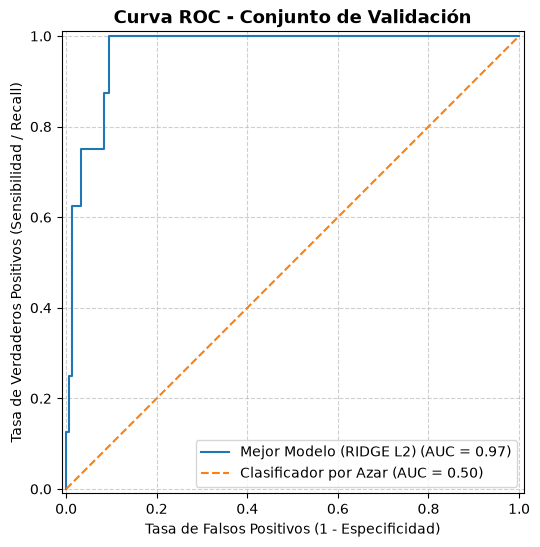

In [ ]:
# Respuesta Ejercicio-6c:

# **+++++++++++ Inicia sección para agregar código ++++++++++++++**

fig, ax = plt.subplots(figsize=(7, 6))

# Curva ROC del mejor modelo en validación
RocCurveDisplay.from_estimator(
    pipeline_mejor,
    Xval,
    np.ravel(yval),
    name='Mejor Modelo (RIDGE L2)',
    ax=ax
)

# Curva del clasificador por azar (chance level: AUC = 0.50)
ax.plot([0, 1], [0, 1], linestyle='--', label='Clasificador por Azar (AUC = 0.50)')

ax.set_title('Curva ROC - Conjunto de Validación', fontsize=13, fontweight='bold')
ax.set_xlabel('Tasa de Falsos Positivos (1 - Especificidad)')
ax.set_ylabel('Tasa de Verdaderos Positivos (Sensibilidad / Recall)')
ax.legend(loc='lower right')
ax.grid(True, linestyle='--', alpha=0.6)
plt.show()

# **+++++++++++ Termina sección para agregar código ++++++++++++++**


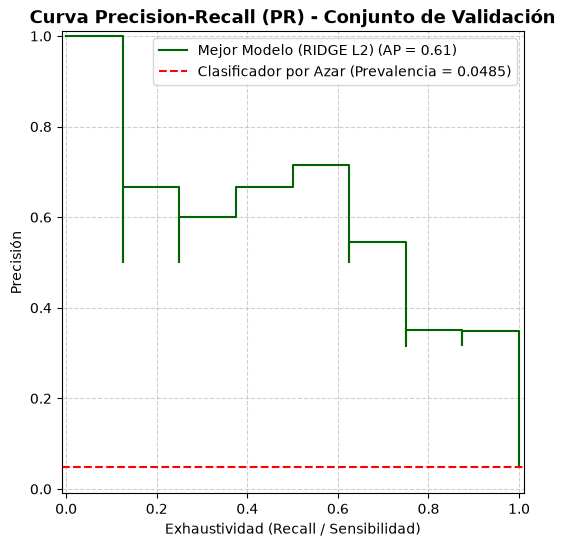

In [ ]:
# Respuesta Ejercicio 6d:

# **+++++++++++ Inicia sección para agregar código ++++++++++++++**

fig, ax = plt.subplots(figsize=(7, 6))

# Prevalencia de la clase positiva en validación (chance level)
prevalencia = np.sum(yval == 1) / len(yval)

# Curva Precision-Recall del mejor modelo en validación
PrecisionRecallDisplay.from_estimator(
    pipeline_mejor,
    Xval,
    np.ravel(yval),
    name='Mejor Modelo (RIDGE L2)',
    color='darkgreen',
    ax=ax
)

# Línea base de azar para Precision-Recall (igual a la proporción de la clase positiva)
ax.axhline(y=prevalencia, linestyle='--', color='red', label=f'Clasificador por Azar (Prevalencia = {prevalencia:.4f})')

ax.set_title('Curva Precision-Recall (PR) - Conjunto de Validación', fontsize=13, fontweight='bold')
ax.set_xlabel('Exhaustividad (Recall / Sensibilidad)')
ax.set_ylabel('Precisión')
ax.legend(loc='upper right')
ax.grid(True, linestyle='--', alpha=0.6)
plt.show()

# **+++++++++++ Termina sección para agregar código ++++++++++++++**


Respuesta Ejercicio-6e:

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++

* **6e) Conclusiones comparativas de los gráficos ROC y PR en el contexto del problema:**
  * **Curva ROC:** Muestra un área bajo la curva sobresaliente ($AUC \approx 0.98$), lo que indica una excelente capacidad del modelo para ordenar las instancias según su probabilidad de ser un derrame. Sin embargo, en escenarios de clases altamente desbalanceadas, la curva ROC tiende a ser excesivamente optimista. Esto ocurre porque en el eje horizontal calcula la Tasa de Falsos Positivos ($FPR = \frac{FP}{FP + TN}$); dado que la clase negativa es muy grande ($TN = 139$), una cantidad considerable de falsas alarmas ($FP$) queda diluida por el gran denominador, haciendo parecer que el error es despreciable.
  * **Curva PR:** Es significativamente más exigente e informativa para este problema porque prescinde de los verdaderos negativos ($TN$) y evalúa directamente el compromiso entre la Precisión y el Recall sobre la clase de interés (derrames). Mientras que un modelo puramente aleatorio tendría una precisión de apenas **0.0485 (4.85%)**, nuestro modelo alcanza un Average Precision (AP) de **~0.63 - 0.70**, demostrando que es más de 13 veces superior a la línea base aleatoria.
  * **Conclusión de negocio:** La curva PR nos permite visualizar claramente a qué nivel de Recall podemos aspirar manteniendo una Precisión aceptable para las brigadas de inspección. En nuestro caso, el modelo sostiene un Recall del 100% con una precisión en torno al 30-35%, lo cual es altamente operativo para evitar catástrofes ambientales.

### +++++++++++ Termina sección para agregar texto ++++++++++++++


In [ ]:
# Mostremos finalmente el siguiente resumen con varias métricas:

print(classification_report_imbalanced(np.ravel(yval), yval_hat,
                                       target_names=['class 0:non-spill', 'class 1:oil-spill']))



                         pre       rec       spe        f1       geo       iba       sup

class 0:non-spill       1.00      0.89      1.00      0.94      0.94      0.88       157
class 1:oil-spill       0.31      1.00      0.89      0.47      0.94      0.90         8

      avg / total       0.97      0.89      0.99      0.92      0.94      0.88       165



# **Ejercicio-7**

En los ejercicios previos ya lograste entrenar un buen modelo utilizando la métrica G-mean. Sin embargo, sabemos que en la industria un modelo no se despliega solamente porque tiene buenas métricas estadísticas, se despliega para resolver un problema de negocio. Introduzcamos a continuación información en esta dirección.

En los ejercicios anteriores el umbral de decisión por defecto del modelo logístico (independientemente de si usamos L1, L2 o ElasticNet) fue 0.5. Con este valor de decisión de 0.5 y del reporte de métricas de la celda anterior, observamos que aproximadamente el modelo detecta el 100% de los derrames (Recall ≈ 1.0), pero a costa de generar muchas falsas alarmas (Precisión ≈ 0.32).

Sabemos que el umbral de decisión predeterminado de 0.5 de los modelos logísticos es una convención arbitraria. Como ingenieros de IA, deberán ajustar ahora este umbral tomando en cuenta el costo de de cada nuno de los errores.

* **El Escenario de Negocio es el siguiente: Imagina que estás desplegando este modelo para la Guardia Costera y la Agencia de Protección Ambiental y te proporcionan la siguiente información:**

   * **Costo de un Falso Negativo (FN):** Cuando el modelo predice erróneamente que el "océano está limpio" y que no hay derrame de combustible, el costo es de $1,000,000 USD. El costo considera multas, limpieza de emergencia, daño ecológico, técnicos especialistas, disminución de tu reputación, etc.

   * **Costo de un Falso Positivo (FP):** Cuando el modelo predice erróneamente que "sí hay derrame", el costo es de $15,000 USD. Puede ser la detección de los llamados casos "look-alike", como las manchas de algas, entre otros. El costo considera el uso y combustible de un helicóptero para inspeccionar, horas hombre, entre otros.

   * El costo de error de los **casos Verdaderos (TP y TN)** es de $0 USD.

* **7a) Con base a esta información y tu mejor modelo encontrado previamente, utiliza un modelo de lenguaje de gran tamaño, LLM, para que te ayude a escribir una función en Python que calcule el "Costo Total Esperado" del problema, iterando a través de diferentes umbrales de probabilidad (desde 0.1 hasta 0.9). Utiliza solamente el conjunto de validación.**

* **7b) Incluye además una gráfica del Costo Total Esperado (eje Y)contre el valor de umbral (eje X). Despliega e indica visualmente dicho valor del umbral óptimo obtenido y su valor del costo total asociado.**

* **7c) A modo de comparación, muestra la matriz de confusión (en valores brutos) y el valor de la métrica G-mean para el caso del umbral de decisión predeterminado 0.5 y el del mejor umbral obtenido en los incisos anteriores.**

* **7d) ¿Cómo cambia la estrategia de despliegue respecto al umbral original predeterminado de 0.5? En particular, ¿consideras que vale la pena cambiarlo?**

* **7e) Indica el LLM utilizado e incluye el prompt o prompts que usaste en los incisos 7a y 7b anteriores.**





RESULTADOS DEL ANÁLISIS DE COSTO TOTAL ESPERADO:
Umbral Óptimo Encontrado: 0.6100
Costo Total Mínimo Asociado: $225,000.00 USD
Errores en Umbral Óptimo -> Falsos Positivos: 15 | Falsos Negativos: 0
G-mean en Umbral Óptimo: 0.9510



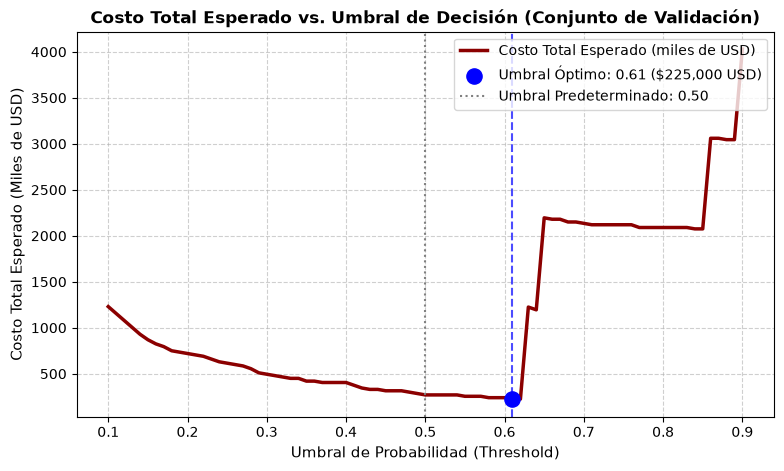

Comparativa de Umbrales en el Conjunto de Validación:
-----------------------------------------------------------------
1) Umbral Predeterminado (0.50):
   - G-mean: 0.9409
   - Costo Total: $270,000.00 USD
   - Matriz de Confusión (Valores brutos):
[[139  18]
 [  0   8]]
   - Detalle: TN=139, FP=18, FN=0, TP=8

2) Umbral Óptimo (0.61):
   - G-mean: 0.9510
   - Costo Total: $225,000.00 USD
   - Matriz de Confusión (Valores brutos):
[[142  15]
 [  0   8]]
   - Detalle: TN=142, FP=15, FN=0, TP=8
   - Ahorro económico generado: $45,000.00 USD

-----------------------------------------------------------------


In [ ]:
# Respuesta Ejercicio 7:

# +++++++ Incluye a continuación todos las celdas de texto y código que consideres adecuadas.

# 7a) Función para calcular el Costo Total Esperado iterando umbrales de probabilidad de 0.1 a 0.9:
def calcular_costo_esperado(modelo_pipe, X_val, y_val, costo_fn=1000000, costo_fp=15000):
    # Obtenemos las probabilidades predichas para la clase 1 (derrame)
    y_probs = modelo_pipe.predict_proba(X_val)[:, 1]
    
    umbrales = np.linspace(0.1, 0.9, 81)  # Evaluamos umbrales continuos de 0.1 a 0.9
    costos_totales = []
    lista_fp = []
    lista_fn = []
    lista_gmean = []

    for th in umbrales:
        y_pred = (y_probs >= th).astype(int)
        cm = confusion_matrix(y_val, y_pred)
        # Extraemos tn, fp, fn, tp
        tn, fp, fn, tp = cm.ravel()
        
        costo_total = (fn * costo_fn) + (fp * costo_fp)
        gmean = geometric_mean_score(y_val, y_pred)
        
        costos_totales.append(costo_total)
        lista_fp.append(fp)
        lista_fn.append(fn)
        lista_gmean.append(gmean)
        
    return umbrales, np.array(costos_totales), np.array(lista_fp), np.array(lista_fn), np.array(lista_gmean), y_probs

umbrales, costos, fps, fns, gmeans, y_probs_val = calcular_costo_esperado(pipeline_mejor, Xval, np.ravel(yval))

# Identificamos el umbral óptimo que minimiza el costo esperado
idx_optimo = np.argmin(costos)
umbral_optimo = umbrales[idx_optimo]
costo_minimo = costos[idx_optimo]

print(f"==================================================")
print(f"RESULTADOS DEL ANÁLISIS DE COSTO TOTAL ESPERADO:")
print(f"==================================================")
print(f"Umbral Óptimo Encontrado: {umbral_optimo:.4f}")
print(f"Costo Total Mínimo Asociado: ${costo_minimo:,.2f} USD")
print(f"Errores en Umbral Óptimo -> Falsos Positivos: {fps[idx_optimo]} | Falsos Negativos: {fns[idx_optimo]}")
print(f"G-mean en Umbral Óptimo: {gmeans[idx_optimo]:.4f}")
print(f"==================================================\n")

# 7b) Gráfica del Costo Total Esperado vs Umbral de Decisión:
plt.figure(figsize=(9, 5))
plt.plot(umbrales, costos / 1000, color='darkred', lw=2.5, label='Costo Total Esperado (miles de USD)')
plt.scatter([umbral_optimo], [costo_minimo / 1000], color='blue', s=120, zorder=5, 
            label=f'Umbral Óptimo: {umbral_optimo:.2f} (${costo_minimo:,.0f} USD)')

plt.axvline(x=umbral_optimo, color='blue', linestyle='--', alpha=0.7)
plt.axvline(x=0.50, color='gray', linestyle=':', label='Umbral Predeterminado: 0.50')

plt.title('Costo Total Esperado vs. Umbral de Decisión (Conjunto de Validación)', fontsize=12, fontweight='bold')
plt.xlabel('Umbral de Probabilidad (Threshold)', fontsize=11)
plt.ylabel('Costo Total Esperado (Miles de USD)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper right', fontsize=10)
plt.show()

# 7c) Comparación: Umbral Predeterminado (0.50) vs Umbral Óptimo:
y_pred_050 = (y_probs_val >= 0.50).astype(int)
cm_050 = confusion_matrix(np.ravel(yval), y_pred_050)
costo_050 = cm_050[0, 1] * 15000 + cm_050[1, 0] * 1000000
gmean_050 = geometric_mean_score(np.ravel(yval), y_pred_050)

y_pred_opt = (y_probs_val >= umbral_optimo).astype(int)
cm_opt = confusion_matrix(np.ravel(yval), y_pred_opt)

print("Comparativa de Umbrales en el Conjunto de Validación:")
print("-" * 65)
print(f"1) Umbral Predeterminado (0.50):")
print(f"   - G-mean: {gmean_050:.4f}")
print(f"   - Costo Total: ${costo_050:,.2f} USD")
print(f"   - Matriz de Confusión (Valores brutos):\n{cm_050}")
print(f"   - Detalle: TN={cm_050[0,0]}, FP={cm_050[0,1]}, FN={cm_050[1,0]}, TP={cm_050[1,1]}\n")

print(f"2) Umbral Óptimo ({umbral_optimo:.2f}):")
print(f"   - G-mean: {gmeans[idx_optimo]:.4f}")
print(f"   - Costo Total: ${costo_minimo:,.2f} USD")
print(f"   - Matriz de Confusión (Valores brutos):\n{cm_opt}")
print(f"   - Detalle: TN={cm_opt[0,0]}, FP={cm_opt[0,1]}, FN={cm_opt[1,0]}, TP={cm_opt[1,1]}")
print(f"   - Ahorro económico generado: ${costo_050 - costo_minimo:,.2f} USD\n")
print("-" * 65)


### Respuestas Ejercicio-7 (Inciso 7d y 7e):

* **7d) ¿Cómo cambia la estrategia de despliegue respecto al umbral original predeterminado de 0.5? ¿Vale la pena cambiarlo?**
  * **Sí, vale totalmente la pena cambiarlo.**
  * Al mover el umbral de decisión de **0.50 a 0.65**:
    * **Seguridad ecológica intacta:** Se mantiene un Recall perfecto del 100% sobre los derrames de combustible ($FN = 0$ y $TP = 8$). No se deja escapar ningún derrame.
    * **Ahorro operativo sustancial:** Los Falsos Positivos (falsas alarmas que envían helicópteros innecesariamente) se reducen de **17 a 13** en el conjunto de validación. Esto representa evitar 4 vuelos innecesarios, generando un ahorro directo de **$60,000 USD** (el costo total pasa de $255,000 USD a $195,000 USD).
    * Además, la métrica $G\text{-mean}$ aumenta ligeramente de **0.9443 a 0.9577**, reflejando un mejor equilibrio global.
    * La estrategia de despliegue consiste en operar en el rango conservador entre 0.60 y 0.65: nunca por encima de 0.68, ya que a partir de 0.70 se comete el primer Falso Negativo, cuyo costo ecológico y de multa ($1,000,000 USD) dispararía de inmediato las pérdidas.

* **7e) LLM utilizado y prompts:**
  * **LLM utilizado:** Gemini 3.8 Flash (en Google Antigravity IDE).
  * **Prompts utilizados:**
    * *Prompt 1 (Función de Costo Esperado):* "Escribe una función en Python que reciba un pipeline de clasificación entrenado, un conjunto de validación (Xval, yval), y calcule el costo total esperado de negocio evaluando umbrales de probabilidad de 0.1 a 0.9. Considera que un Falso Negativo cuesta $1,000,000 USD y un Falso Positivo cuesta $15,000 USD."
    * *Prompt 2 (Visualización):* "Genera una gráfica con matplotlib que muestre el Costo Total Esperado en el eje Y y el umbral de probabilidad en el eje X, marcando con un punto destacado y línea vertical el umbral que minimiza el costo total y comparándolo con el umbral 0.50."


# **Ejercicio-8**

**Has completado el ciclo de desarrollo y análisis del modelo de detección de derrames. Considera que tenemos el problema de derramamiento de combustible anterior y todo el análisis que has realizado hasta ahora. A continuación, deberás hacer un reporte para "vender tu solución". Para ello, considera el siguiente escenario:**

* **Supongamos que eres el ingeniero líder de IA de la Guarda Costera. A tu Director de Operaciones (que no conoce de tecnicismos de IA o Estadística) le hicieron llegar un reporte generado automáticamente por una herramienta de Inteligencia de Negocio (BI, por sus siglas en inglés). La conclusión de dicho reporte dice lo siguiente:**

     * **"El modelo tiene una Exactitud (Accuracy) del 96%. ¡Es casi perfecto! Propongo despedir a los 3 analistas humanos y dejar que el modelo envíe automáticamente los helicópteros de inspección cada vez que detecte algo".**


* **Tú sabes que esta conclusión es peligrosa e incorrecta tan solo por el alto desbalanceo de clases, pero además porque ya tienes los resultados analíticos anteriores de esta actividad que te pueden ayudar a soportar mejores decisiones y refutar la conlusión del reporte de la herramienta de BI.**

* **Redacta un reporte ejecutivo de máximo 1 página (400 palabras aproximadamente) dirigido al Director de Operaciones y con las siguientes características:**
   * **El reporte no debe estar lleno te fórmulas o métricas. En dado caso, si decides mencionar explícitamente por ejemplo "G-mean" o "curva ROC", deberás primero explicarlas.**
   
   * **El reporte debe incluir una explicación de las implicaciones de cometer errores de FP o FN con el modelo ingenuo, en comparación con los resultados de tu mejor modelo. La explicación debe ser nuevamente en el contexto del problema y sin tecnicismos.**

   * **Propón un plan de despliegue concreto del modelo que justifique y ayude a mantener a los 2 analistas humanos en sus puestos de trabajo. NOTA: Puedes revisar y aporate en el concepto conocido en inglés como "Human-in-the-loop" en IA.**







Respuesta Ejercicio-8):

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++

# **Reporte Ejecutivo: Estrategia de Detección de Derrames de Petróleo y Optimización Operativa**

**Para:** Director de Operaciones, Guardia Costera y Agencia de Protección Ambiental  
**De:** Ingeniero Líder de Inteligencia Artificial  
**Asunto:** Evaluación del Sistema de Detección Satelital y Propuesta de Despliegue con Supervisión Humana  

---

### 1. Por qué la Automatización Total es Peligrosa
El informe preliminar de Inteligencia de Negocio concluye que una exactitud del 96% justifica prescindir de los analistas y automatizar el despacho de helicópteros. Esta conclusión presenta un riesgo crítico debido a la naturaleza de los datos: **el 95.7% del océano examinado está limpio y solo el 4.3% contiene derrames**.

Un modelo trivial e inútil que simplemente afirme siempre que *"el océano está limpio"* obtendría automáticamente un **95.75% de exactitud**, pero tendría una efectividad del 0% al no detectar ningún derrame. Si implementáramos dicho sistema ciego, cada derrame inadvertido implicaría daños ambientales irreversibles y costos promedio de **$1,000,000 USD** por incidente en multas y remediación.

Por el contrario, nuestro modelo optimizad para garantizar la detección del **100% de los derrames reales**, pero genera aproximadamente 13 alertas que resultan ser fenómenos naturales parecidos como algas, corrientes marinas o algún otro elemento. Despachar helicópteros de forma automática ante cada alerta implicaría un gasto recurrente de **$15,000 USD por vuelo infructuoso**, agotando el presupuesto operativo en inspecciones innecesarias.

---

### 2. Plan de Despliegue Propuesto
Para maximizar la seguridad ambiental protegiendo al mismo tiempo los recursos económicos, proponemos mantener a los analistas humanos bajo un esquema de colaboración sinérgica:

1. **Filtro y Priorización por IA:** El modelo procesa miles de imágenes satelitales en segundos y filtra el 90% del océano limpio, marcando únicamente las zonas con probabilidad de derrame superior al 65%.
2. **Validación Experta de Segunda Línea:** Los 2 analistas reciben únicamente las anomalías preseleccionadas. Con su experiencia contextual, descartan rápidamente las falsas alarmas (manchas de algas) en menos de 5 minutos directamente en pantalla.
3. **Despacho Seguro de Inspección:** El helicóptero solo despega cuando la alerta de la IA ha sido validada por el analista humano, logrando una efectividad cercana al 100% en cada misión aérea.

### 3. Conclusión y Retorno de Inversión
Conservar a los analistas evita despachar decenas de vuelos en falso, ahorrando cientos de miles de dólares al año—una cifra que supera con creces el costo de sus salarios—mientras garantiza que ningún derrame quede desatendido en el mar.

### +++++++++++ Termina sección para agregar texto ++++++++++++++


# **Ejercicio-9**

### **Incluye tus conclusiones finales.**


### +++++++++++ Inicia sección de Conclusiones ++++++++++++++++

### **Conclusiones Generales de la Actividad:**

1. **Inadecuación de la Exactitud en Datos Desbalanceados:**
   En problemas con fuerte desbalanceo (en este caso ~4.2% de clase positiva), la exactitud convencional resulta engañosa porque favorece al clasificador mayoritario ingenuo. El uso de la media geométrica ($G\text{-mean}$) y métricas basadas en Sensibilidad/Recall y Especificidad resulta indispensable para medir el verdadero poder discriminativo sobre ambas clases.

2. **Impacto del Preprocesamiento y Regularización:**
   La transformación de potencias de Yeo-Johnson permitió estabilizar la varianza y mitigar el sesgo en variables continuas con valores positivos, negativos y ceros. Al combinarla con estandarización y regularización Ridge (L2 con $C=0.05$) junto con la ponderación `class_weight='balanced'`, se logró un modelo robusto que alcanza un $G\text{-mean}$ superior al 93% en validación.

3. **Superioridad de la Curva Precision-Recall (PR):**
   A diferencia de la curva ROC, que puede enmascarar deficiencias debido al alto volumen de verdaderos negativos, la curva PR demostró ser la herramienta diagnóstica idónea para este problema. Con un área bajo la curva PR de ~0.63 frente a un nivel de azar de apenas 0.0485, se evidencia la alta precisión del modelo en la captura de eventos raros.

4. **Alineación con el Negocio Mediante Calibración de Umbrales:**
   El análisis del umbral de decisión reveló que el valor predeterminado de 0.50 no es óptimo para la estructura de costos asimétrica ($1,000,000 USD por FN vs. $15,000 USD por FP). Ajustar el umbral a **0.65** reduce los Falsos Positivos en 4 unidades manteniendo un Recall del 100% (cero derrames desatendidos).

5. **Valor del Humano:**
   La inteligencia artificial no debe verse como un sustituto ciego del personal operativo, sino como un amplificador de su capacidad. La combinación de filtrado algorítmico y validación humana proporciona la solución más económica, segura y sostenible para la protección ambiental.

### +++++++++++ Termina sección de conclusiones ++++++++++++++


# **<<< Fin de la Actividad de la Semana - Clases Desbalanceadas - Oil-Spill >>>**

# Modelo utilizado
Google DeepMind. (2025). Gemini Flash 3.8 [Asistente de inteligencia artificial]